In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

plt.rcParams['figure.figsize'] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train.csv


In [3]:
df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
print("Dataset Shape:", df.shape)

print("Total Rows:", df.shape[0])

print("Total Columns:", df.shape[1])

Dataset Shape: (1460, 81)
Total Rows: 1460
Total Columns: 81


In [5]:
display(df.head())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [7]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [8]:
missing_percentage = (missing / len(df)) * 100

missing_table = pd.DataFrame({
    'Missing Values': missing,
    'Missing Percentage': missing_percentage
})

display(missing_table)

,Missing Values,Missing Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


In [9]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

print("Total Numerical Columns:", len(numeric_cols))

print(numeric_cols)

Total Numerical Columns: 38
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']


In [10]:
categorical_cols = df.select_dtypes(include='object').columns.tolist()

print("Total Categorical Columns:", len(categorical_cols))

print(categorical_cols)

Total Categorical Columns: 43
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


In [11]:
ordinal_cols = [
    'OverallQual',
    'ExterQual',
    'KitchenQual'
]

print("Ordinal Variables:")

for col in ordinal_cols:
    print(col)

Ordinal Variables:
OverallQual
ExterQual
KitchenQual


In [12]:
ordinal_map = {
    'ExterQual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'KitchenQual': ['Po', 'Fa', 'TA', 'Gd', 'Ex']
}

for col, order in ordinal_map.items():
    df[col] = pd.Categorical(
        df[col],
        categories=order,
        ordered=True
    )

print("Ordinal variables converted successfully!")

Ordinal variables converted successfully!


In [13]:
summary = []

for col in df.columns:

    if col in ordinal_cols:
        variable_type = 'Ordinal'
    elif col in numeric_cols:
        variable_type = 'Numerical'
    else:
        variable_type = 'Categorical'

    unique_values = df[col].nunique()

    examples = df[col].dropna().unique()[:5]

    summary.append({
        'Column Name': col,
        'Variable Type': variable_type,
        'Unique Values': unique_values,
        'Example Values': ', '.join(map(str, examples))
    })

variable_summary = pd.DataFrame(summary)

display(variable_summary)

,Column Name,Variable Type,Unique Values,Example Values
0,Id,Numerical,1460,"1, 2, 3, 4, 5"
1,MSSubClass,Numerical,15,"60, 20, 70, 50, 190"
2,MSZoning,Categorical,5,"RL, RM, C (all), FV, RH"
3,LotFrontage,Numerical,110,"65.0, 80.0, 68.0, 60.0, 84.0"
4,LotArea,Numerical,1073,"8450, 9600, 11250, 9550, 14260"
...,...,...,...,...
76,MoSold,Numerical,12,"2, 5, 9, 12, 10"
77,YrSold,Numerical,5,"2008, 2007, 2006, 2009, 2010"
78,SaleType,Categorical,9,"WD, New, COD, ConLD, ConLI"
79,SaleCondition,Categorical,6,"Normal, Abnorml, Partial, AdjLand, Alloca"


In [14]:
print("Numerical Columns:", len(numeric_cols))
print("Categorical Columns:", len(categorical_cols))
print("Ordinal Columns:", len(ordinal_cols))

print("Total Dataset Columns:", len(df.columns))

Numerical Columns: 38
Categorical Columns: 43
Ordinal Columns: 3
Total Dataset Columns: 81


In [15]:
display(df.describe())

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [16]:
columns = ['SalePrice', 'GrLivArea', 'LotArea']

for col in columns:

    print("\nStatistics for:", col)

    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])
    print("Standard Deviation:", df[col].std())
    print("Variance:", df[col].var())
    print("Range:", df[col].max() - df[col].min())
    print("IQR:", df[col].quantile(0.75) - df[col].quantile(0.25))
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())


Statistics for: SalePrice
Mean: 180921.19589041095
Median: 163000.0
Mode: 140000
Standard Deviation: 79442.50288288663
Variance: 6311111264.297451
Range: 720100
IQR: 84025.0
Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529

Statistics for: GrLivArea
Mean: 1515.463698630137
Median: 1464.0
Mode: 864
Standard Deviation: 525.4803834232027
Variance: 276129.63336259616
Range: 5308
IQR: 647.25
Skewness: 1.3665603560164552
Kurtosis: 4.895120580693174

Statistics for: LotArea
Mean: 10516.828082191782
Median: 9478.5
Mode: 7200
Standard Deviation: 9981.264932379147
Variance: 99625649.6503417
Range: 213945
IQR: 4048.0
Skewness: 12.207687851233496
Kurtosis: 203.24327101886033


In [17]:
for col in columns:

    mean_value = df[col].mean()
    median_value = df[col].median()

    print("\nColumn:", col)
    print("Mean:", mean_value)
    print("Median:", median_value)

    if mean_value > median_value:
        print("Distribution may be right-skewed")

    elif mean_value < median_value:
        print("Distribution may be left-skewed")

    else:
        print("Mean and median are equal")


Column: SalePrice
Mean: 180921.19589041095
Median: 163000.0
Distribution may be right-skewed

Column: GrLivArea
Mean: 1515.463698630137
Median: 1464.0
Distribution may be right-skewed

Column: LotArea
Mean: 10516.828082191782
Median: 9478.5
Distribution may be right-skewed


In [18]:
print("Neighborhood Value Counts:")
display(df['Neighborhood'].value_counts())

print("Neighborhood Mode:")
print(df['Neighborhood'].mode()[0])

print("HouseStyle Value Counts:")
display(df['HouseStyle'].value_counts())

print("HouseStyle Mode:")
print(df['HouseStyle'].mode()[0])

Neighborhood Value Counts:


,count
Neighborhood,
NAmes,225
CollgCr,150
OldTown,113
Edwards,100
Somerst,86
Gilbert,79
NridgHt,77
Sawyer,74
NWAmes,73


Neighborhood Mode:
NAmes
HouseStyle Value Counts:


,count
HouseStyle,
1Story,726
2Story,445
1.5Fin,154
SLvl,65
SFoyer,37
1.5Unf,14
2.5Unf,11
2.5Fin,8


HouseStyle Mode:
1Story


In [19]:
statistics = []

for col in columns:

    statistics.append({
        'Feature': col,
        'Mean': df[col].mean(),
        'Median': df[col].median(),
        'Mode': df[col].mode()[0],
        'Standard Deviation': df[col].std(),
        'Variance': df[col].var(),
        'Range': df[col].max() - df[col].min(),
        'IQR': df[col].quantile(0.75) - df[col].quantile(0.25),
        'Skewness': df[col].skew(),
        'Kurtosis': df[col].kurt()
    })

statistics_df = pd.DataFrame(statistics)

display(statistics_df.round(3))

,Feature,Mean,Median,Mode,Standard Deviation,Variance,Range,IQR,Skewness,Kurtosis
0,SalePrice,180921.196,163000.0,140000,79442.503,6.311111e+09,720100,84025.00,1.883,6.536
1,GrLivArea,1515.464,1464.0,864,525.480,2.761296e+05,5308,647.25,1.367,4.895
2,LotArea,10516.828,9478.5,7200,9981.265,9.962565e+07,213945,4048.00,12.208,203.243


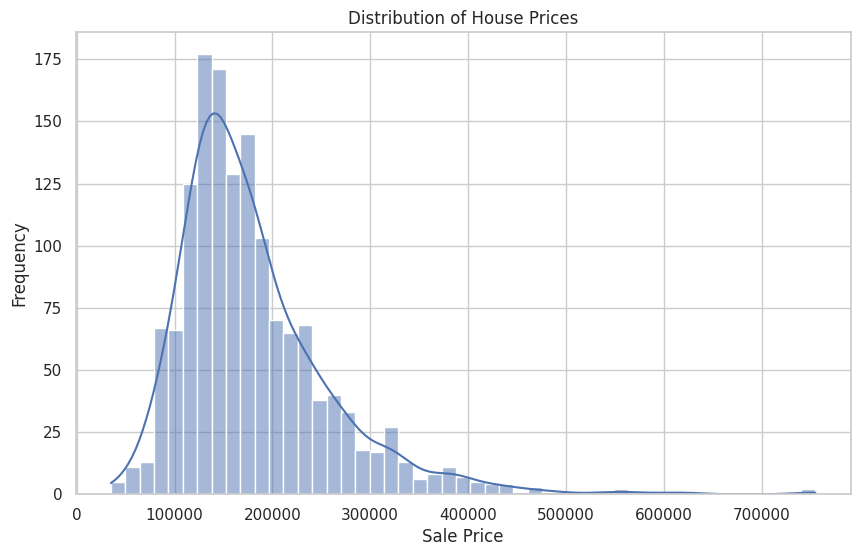

In [20]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='SalePrice',
    kde=True
)

plt.title("Distribution of House Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.show()

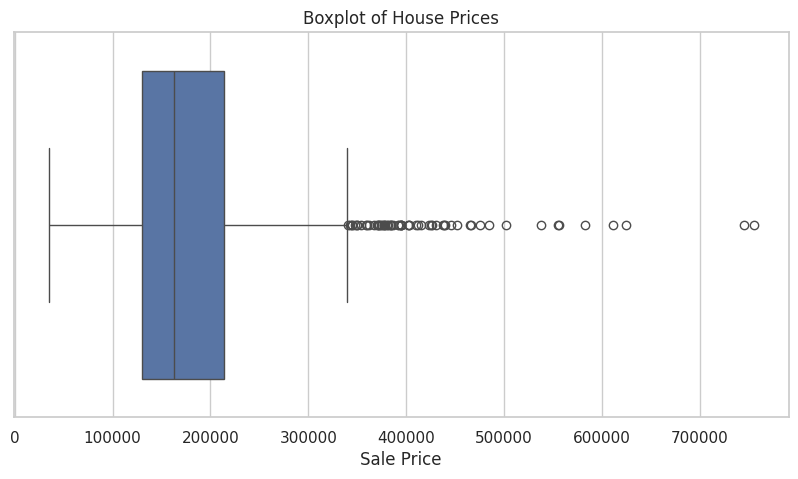

In [21]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df['SalePrice']
)

plt.title("Boxplot of House Prices")
plt.xlabel("Sale Price")

plt.show()

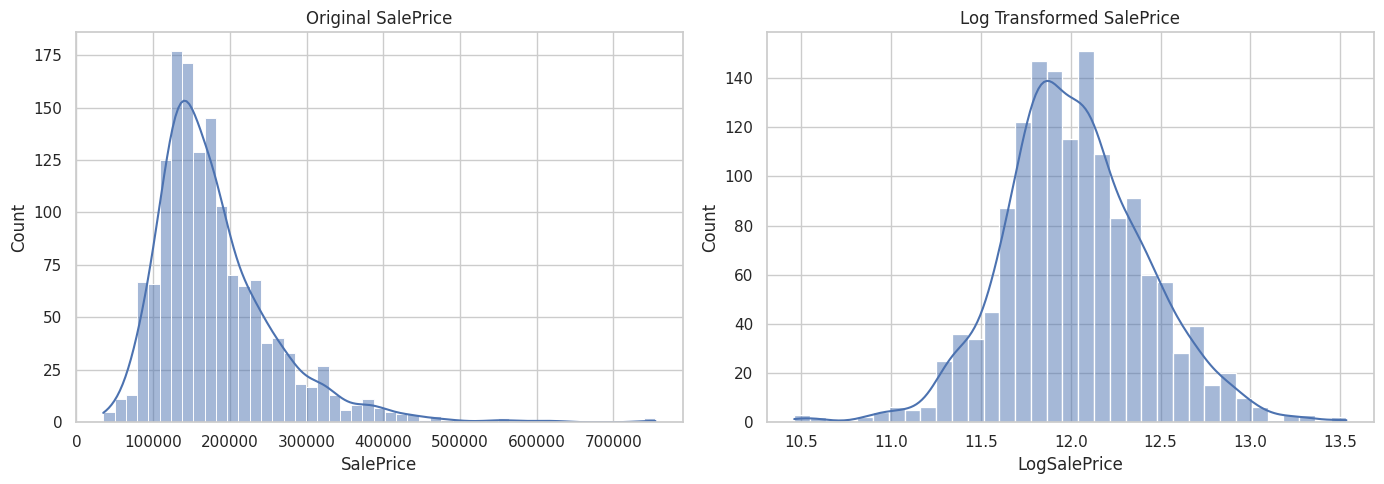

Original Skewness: 1.8828757597682129
Log Skewness: 0.12134661989685333


In [22]:
df['LogSalePrice'] = np.log1p(df['SalePrice'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x='SalePrice',
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Original SalePrice")

sns.histplot(
    data=df,
    x='LogSalePrice',
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Log Transformed SalePrice")

plt.tight_layout()
plt.show()

print("Original Skewness:", df['SalePrice'].skew())
print("Log Skewness:", df['LogSalePrice'].skew())

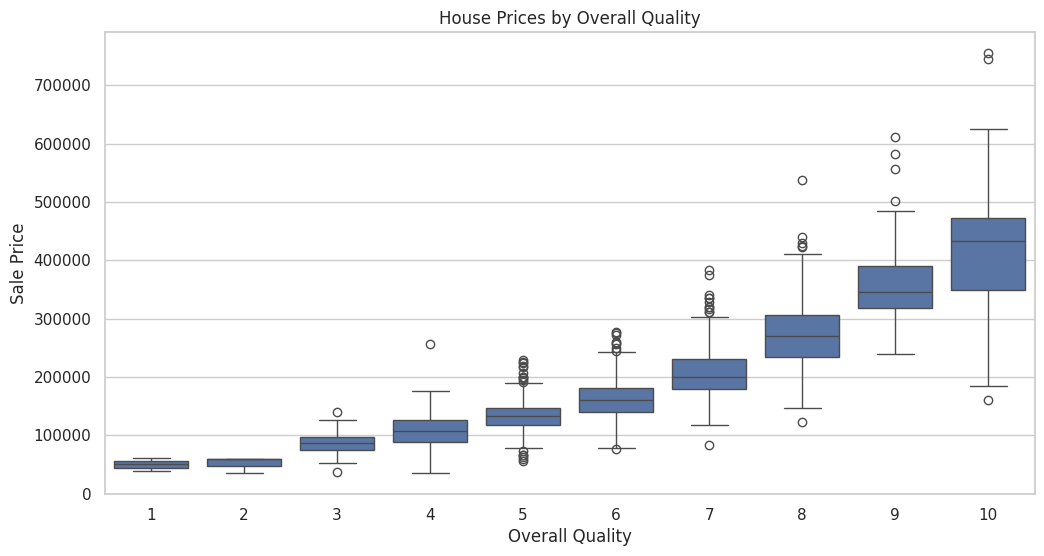

In [23]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='OverallQual',
    y='SalePrice'
)

plt.title("House Prices by Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")

plt.show()

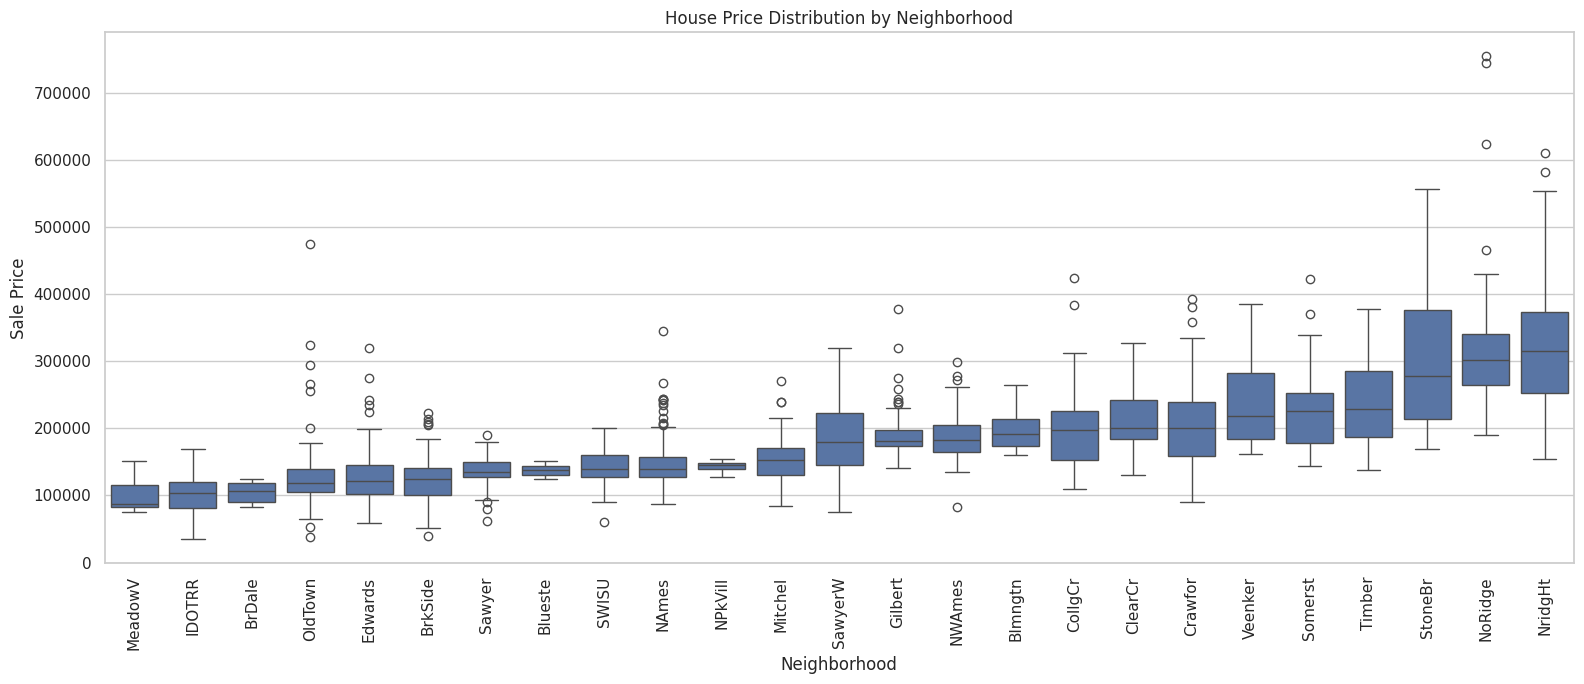

In [24]:
neighborhood_order = (
    df.groupby('Neighborhood')['SalePrice']
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(16, 7))

sns.boxplot(
    data=df,
    x='Neighborhood',
    y='SalePrice',
    order=neighborhood_order
)

plt.title("House Price Distribution by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Sale Price")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

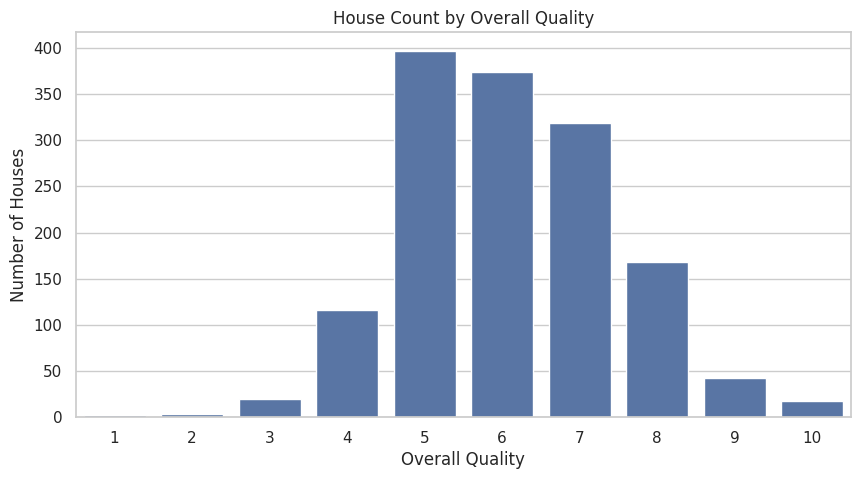

In [25]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='OverallQual'
)

plt.title("House Count by Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Number of Houses")

plt.show()

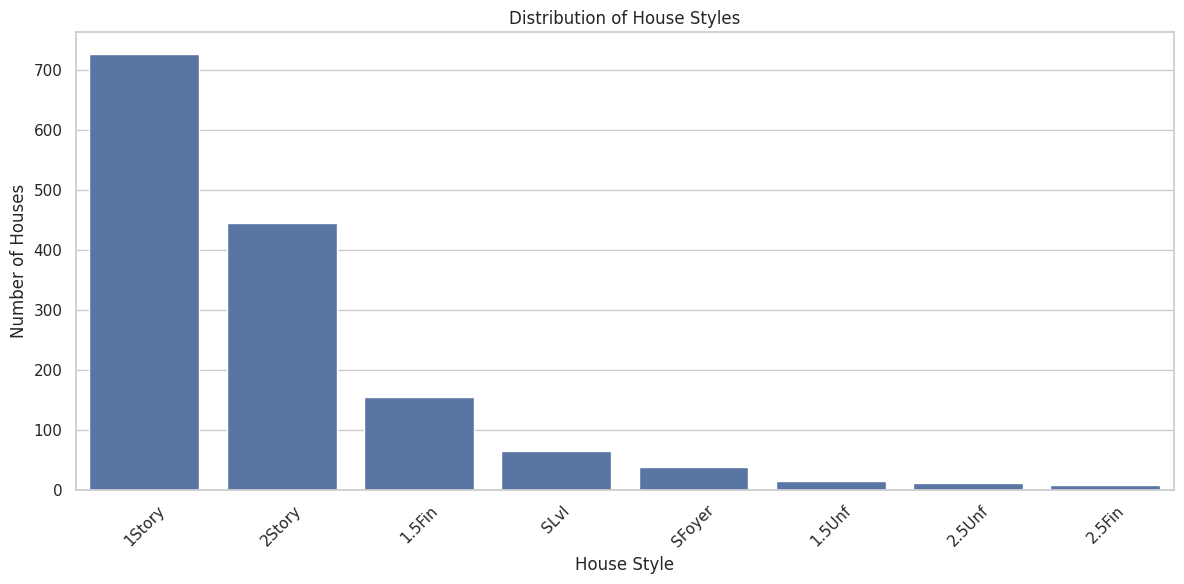

In [26]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='HouseStyle',
    order=df['HouseStyle'].value_counts().index
)

plt.title("Distribution of House Styles")
plt.xlabel("House Style")
plt.ylabel("Number of Houses")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [27]:
numeric_df = df.select_dtypes(include=np.number)

cov_matrix = numeric_df.cov()

display(cov_matrix)

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice,LogSalePrice
Id,177755.000000,198.968472,-108.390207,-1.398197e+05,-16.539068,5.915696,-1.618818e+02,-191.474297,-3.842688e+03,-9.661021e+02,...,-1.332214e+01,74.450651,-576.428376,31.270391,966.275531,-1305.726525,24.133653,0.398561,-7.340732e+05,-3.021719
MSSubClass,198.968472,1789.338306,-404.439075,-5.901742e+04,1.908771,-2.792117,3.558134e+01,35.439934,1.758378e+02,-1.347356e+03,...,-1.709661e+01,-31.119180,-54.348569,-61.394007,14.076652,-161.243759,-1.553607,-1.202630,-2.832337e+05,-1.249683
LotFrontage,-108.390207,-404.439075,589.749169,8.199814e+04,8.673047,-1.573935,9.510848e+01,45.744675,8.712074e+02,2.635953e+03,...,2.438681e+02,16.022614,48.936214,56.264418,194.586364,15.520479,0.735389,0.240700,7.124262e+05,3.595613
LotArea,-139819.667238,-59017.418634,81998.138404,9.962565e+07,1460.548271,-62.602871,4.289113e+03,2841.343594,1.884014e+05,9.746908e+05,...,5.606253e+04,-11188.088772,5976.210971,24020.024881,31148.209380,188508.749657,32.517342,-189.050203,2.092111e+08,1025.937421
OverallQual,-16.539068,1.908771,8.673047,1.460548e+03,1.912679,-0.141484,2.390622e+01,15.723417,1.030121e+02,1.511770e+02,...,2.829764e+01,-9.630806,1.231398,5.003537,3.620945,-21.548945,0.264785,-0.050229,8.690413e+04,0.451443
OverallCond,5.915696,-2.792117,-1.573935,-6.260287e+01,-0.141484,1.238322,-1.263671e+01,1.694152,-2.581896e+01,-2.346427e+01,...,-2.402762e+00,4.785160,0.832039,3.400819,-0.088745,37.970669,-0.010563,0.064953,-6.882739e+03,-0.016388
YearBuilt,-161.881768,35.581337,95.108483,4.289113e+03,23.906215,-12.636709,9.122154e+02,369.675456,1.725993e+03,3.437028e+03,...,3.775838e+02,-714.886948,27.763434,-84.815514,6.006353,-515.209195,1.012426,-0.546237,1.254637e+06,7.076693
YearRemodAdd,-191.474297,35.439934,45.744675,2.841344e+03,15.723417,1.694152,3.696755e+02,426.232822,6.716764e+02,1.209533e+03,...,3.095486e+02,-244.692937,27.410061,-44.594964,4.835329,-105.358566,1.199517,0.980046,8.317079e+05,4.664450
MasVnrArea,-3842.687941,175.837842,871.207424,1.884014e+05,103.012054,-25.818956,1.725993e+03,671.676358,3.278497e+04,2.182760e+04,...,1.503301e+03,-1218.999064,100.044636,622.125969,85.516034,-2685.666442,-2.915638,-1.973363,6.854858e+06,31.152156
BsmtFinSF1,-966.102125,-1347.355751,2635.952669,9.746908e+05,151.176998,-23.464270,3.437028e+03,1209.532821,2.182760e+04,2.080255e+05,...,3.377322e+03,-2851.840396,353.685020,1577.237193,2574.473738,808.155748,-19.393195,8.697797,1.400137e+07,67.778191


In [28]:
corr_matrix = numeric_df.corr(method='pearson')

display(corr_matrix)

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice,LogSalePrice
Id,1.000000,0.011156,-0.010601,-0.033226,-0.028365,0.012609,-0.012713,-0.021998,-0.050298,-0.005024,...,-0.000477,0.002889,-0.046635,0.001330,0.057044,-0.006242,0.021172,0.000712,-0.021917,-0.017942
MSSubClass,0.011156,1.000000,-0.386347,-0.139781,0.032628,-0.059316,0.027850,0.040581,0.022936,-0.069836,...,-0.006100,-0.012037,-0.043825,-0.026030,0.008283,-0.007683,-0.013585,-0.021407,-0.084284,-0.073959
LotFrontage,-0.010601,-0.386347,1.000000,0.426095,0.251646,-0.059213,0.123349,0.088866,0.193458,0.233633,...,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799,0.355879
LotArea,-0.033226,-0.139781,0.426095,1.000000,0.105806,-0.005636,0.014228,0.013788,0.104160,0.214103,...,0.084774,-0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,-0.014261,0.263843,0.257320
OverallQual,-0.028365,0.032628,0.251646,0.105806,1.000000,-0.091932,0.572323,0.550684,0.411876,0.239666,...,0.308819,-0.113937,0.030371,0.064886,0.065166,-0.031406,0.070815,-0.027347,0.790982,0.817185
OverallCond,0.012609,-0.059316,-0.059213,-0.005636,-0.091932,1.000000,-0.375983,0.073741,-0.128101,-0.046231,...,-0.032589,0.070356,0.025504,0.054811,-0.001985,0.068777,-0.003511,0.043950,-0.077856,-0.036868
YearBuilt,-0.012713,0.027850,0.123349,0.014228,0.572323,-0.375983,1.000000,0.592855,0.315707,0.249503,...,0.188686,-0.387268,0.031355,-0.050364,0.004950,-0.034383,0.012398,-0.013618,0.522897,0.586570
YearRemodAdd,-0.021998,0.040581,0.088866,0.013788,0.550684,0.073741,0.592855,1.000000,0.179618,0.128451,...,0.226298,-0.193919,0.045286,-0.038740,0.005829,-0.010286,0.021490,0.035743,0.507101,0.565608
MasVnrArea,-0.050298,0.022936,0.193458,0.104160,0.411876,-0.128101,0.315707,0.179618,1.000000,0.264736,...,0.125703,-0.110204,0.018796,0.061466,0.011723,-0.029815,-0.005965,-0.008201,0.477493,0.430809
BsmtFinSF1,-0.005024,-0.069836,0.233633,0.214103,0.239666,-0.046231,0.249503,0.128451,0.264736,1.000000,...,0.111761,-0.102303,0.026451,0.062021,0.140491,0.003571,-0.015727,0.014359,0.386420,0.372023


In [29]:
top_corr = (
    corr_matrix['SalePrice']
    .drop('SalePrice')
    .abs()
    .sort_values(ascending=False)
)

print("Top 10 Features Correlated with SalePrice:")

display(top_corr.head(10))

Top 10 Features Correlated with SalePrice:


,SalePrice
LogSalePrice,0.948374
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897


In [30]:
top3 = top_corr.head(3).index

for col in top3:

    print("\nFeature:", col)

    print(
        "Covariance with SalePrice:",
        df[col].cov(df['SalePrice'])
    )

    print(
        "Correlation with SalePrice:",
        df[col].corr(df['SalePrice'])
    )


Feature: LogSalePrice
Covariance with SalePrice: 30095.001246838507
Correlation with SalePrice: 0.9483743770902764

Feature: OverallQual
Covariance with SalePrice: 86904.12583679947
Correlation with SalePrice: 0.7909816005838044

Feature: GrLivArea
Covariance with SalePrice: 29581866.743236605
Correlation with SalePrice: 0.7086244776126523


In [31]:
comparison = []

for col in top3:

    comparison.append({
        'Feature': col,
        'Covariance': df[col].cov(df['SalePrice']),
        'Correlation': df[col].corr(df['SalePrice'])
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(3))

,Feature,Covariance,Correlation
0,LogSalePrice,3.009500e+04,0.948
1,OverallQual,8.690413e+04,0.791
2,GrLivArea,2.958187e+07,0.709


In [32]:
spearman_corr = df[
    ['OverallQual', 'SalePrice']
].corr(method='spearman')

display(spearman_corr)

,OverallQual,SalePrice
OverallQual,1.000000,0.809829
SalePrice,0.809829,1.000000


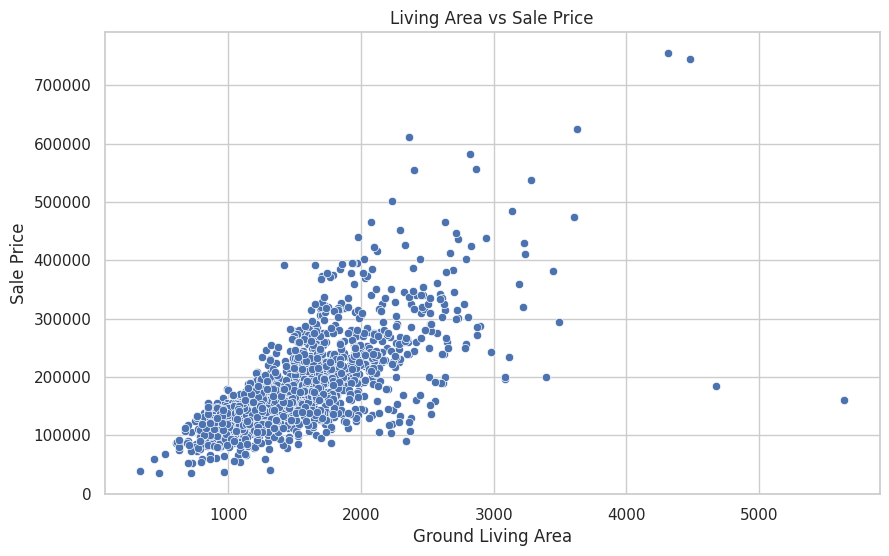

In [33]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='GrLivArea',
    y='SalePrice'
)

plt.title("Living Area vs Sale Price")
plt.xlabel("Ground Living Area")
plt.ylabel("Sale Price")

plt.show()

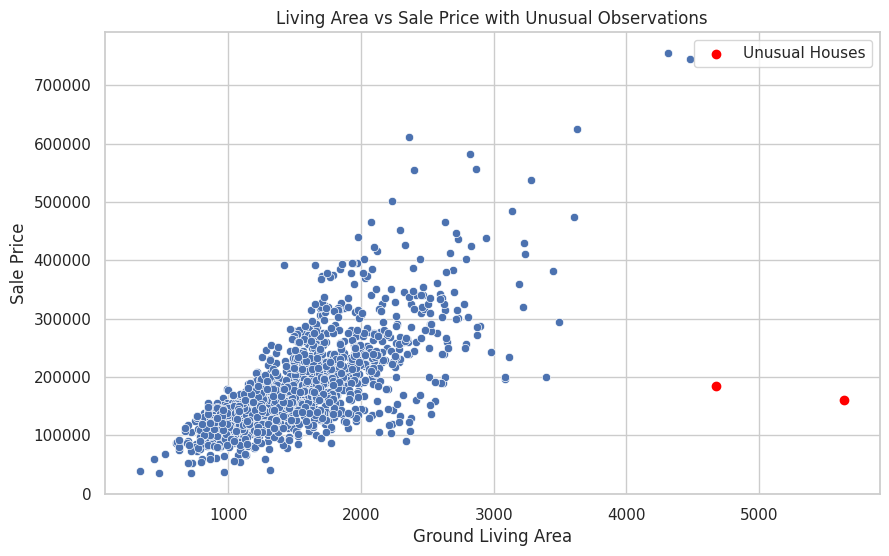

Number of unusual observations: 2


In [34]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='GrLivArea',
    y='SalePrice'
)

outliers = df[
    (df['GrLivArea'] > 4000) &
    (df['SalePrice'] < 300000)
]

plt.scatter(
    outliers['GrLivArea'],
    outliers['SalePrice'],
    color='red',
    label='Unusual Houses'
)

plt.title("Living Area vs Sale Price with Unusual Observations")
plt.xlabel("Ground Living Area")
plt.ylabel("Sale Price")

plt.legend()
plt.show()

print("Number of unusual observations:", len(outliers))

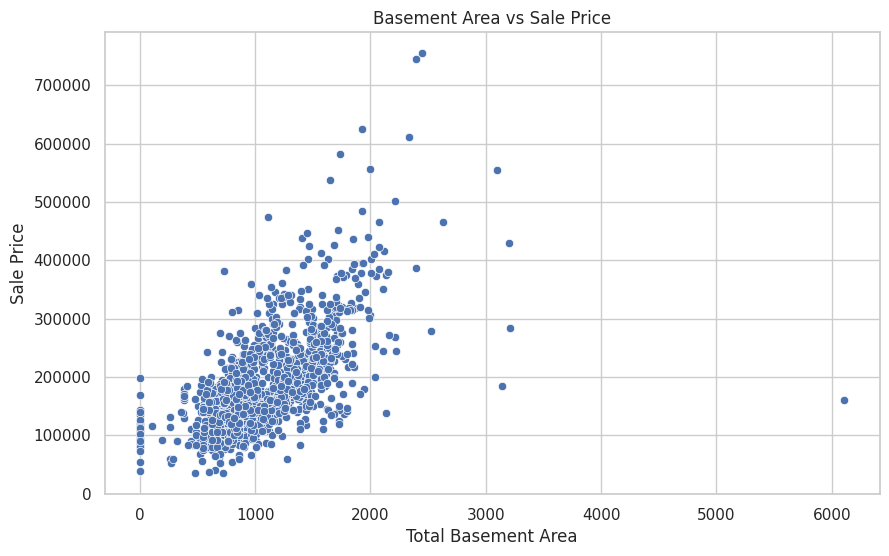

In [35]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='TotalBsmtSF',
    y='SalePrice'
)

plt.title("Basement Area vs Sale Price")
plt.xlabel("Total Basement Area")
plt.ylabel("Sale Price")

plt.show()

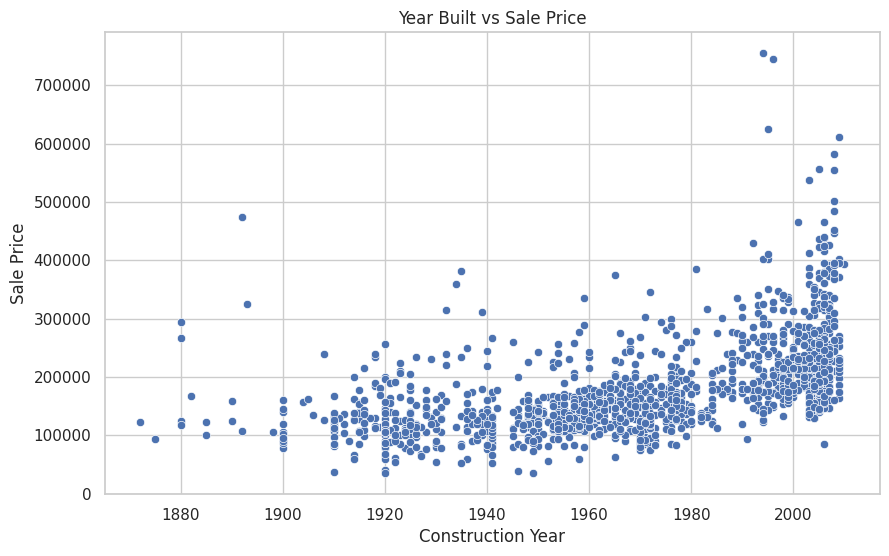

In [36]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='YearBuilt',
    y='SalePrice'
)

plt.title("Year Built vs Sale Price")
plt.xlabel("Construction Year")
plt.ylabel("Sale Price")

plt.show()

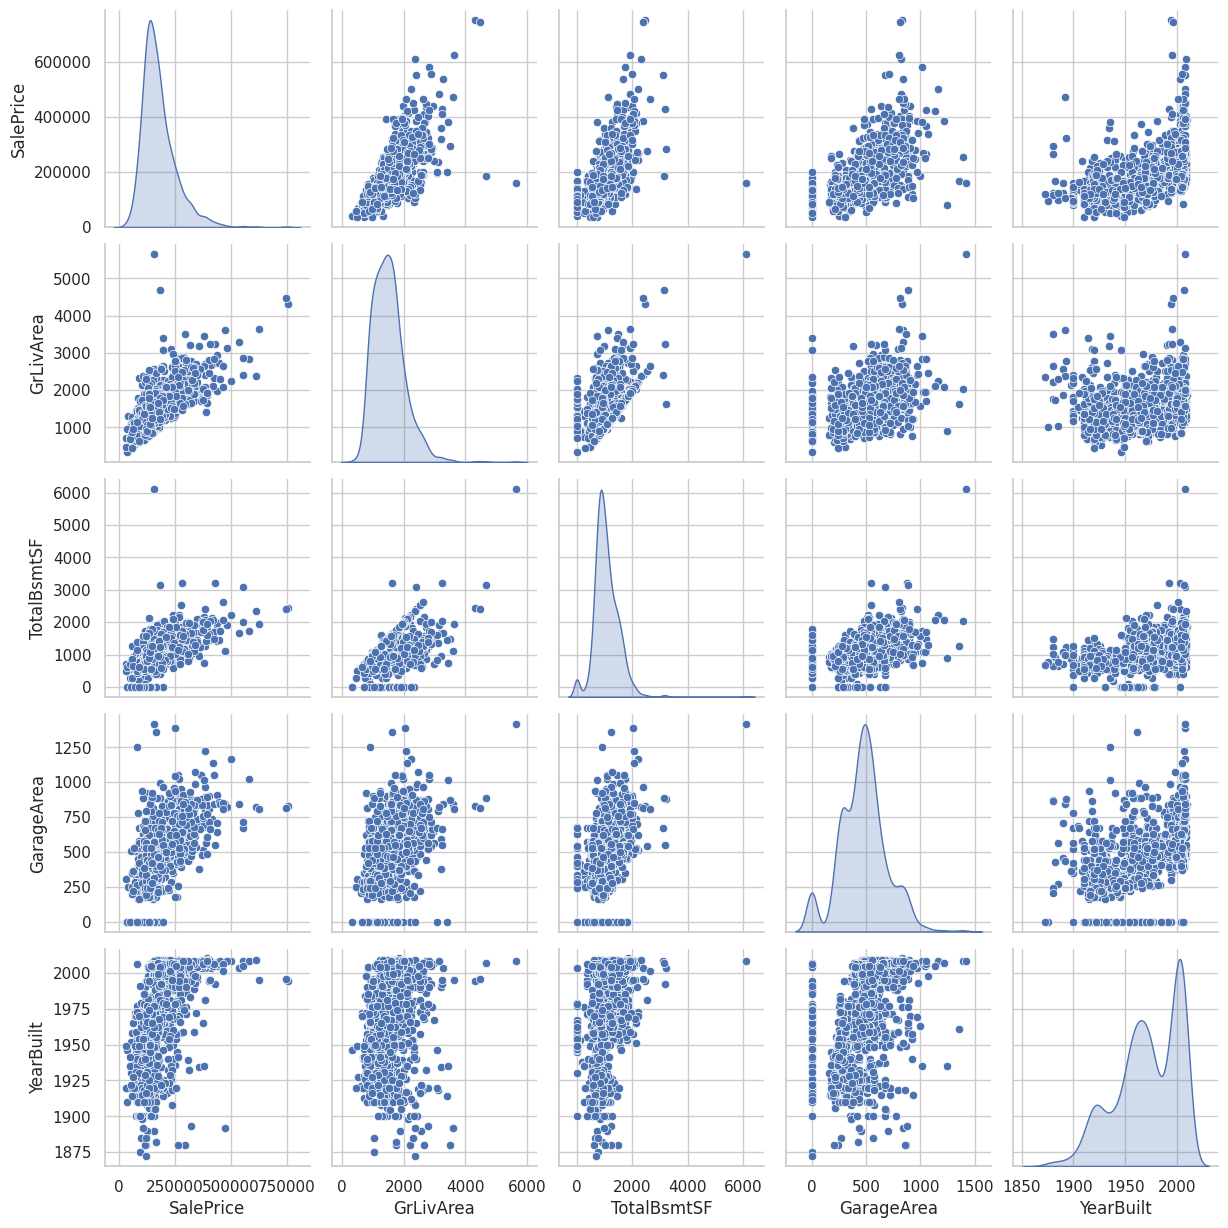

In [37]:
selected = [
    'SalePrice',
    'GrLivArea',
    'TotalBsmtSF',
    'GarageArea',
    'YearBuilt'
]

sns.pairplot(
    df[selected].dropna(),
    diag_kind='kde'
)

plt.show()

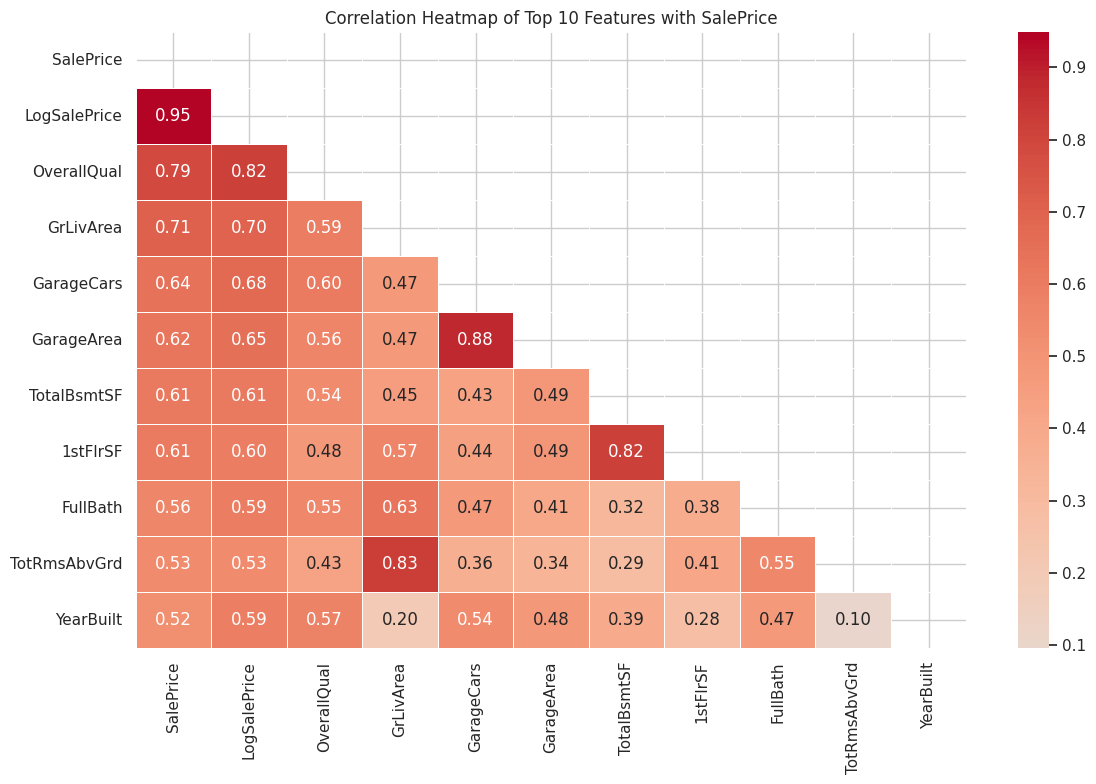

In [38]:
top10_features = top_corr.head(10).index.tolist()
heatmap_features = ['SalePrice'] + top10_features

plt.figure(figsize=(12, 8))

corr_subset = df[heatmap_features].corr()

mask = np.triu(np.ones_like(corr_subset, dtype=bool))

sns.heatmap(
    corr_subset,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Correlation Heatmap of Top 10 Features with SalePrice')
plt.tight_layout()
plt.show()

In [39]:
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)].index

def zscore_outliers(series, threshold=3):
    z = (series - series.mean()) / series.std()
    return series[abs(z) > threshold].index

for col in ['GrLivArea', 'SalePrice']:
    iqr_indices = iqr_outliers(df[col])
    zscore_indices = zscore_outliers(df[col])

    print(col)
    print("IQR outliers:", len(iqr_indices))
    print("Z-score outliers:", len(zscore_indices))
    print("Overlap:", len(set(iqr_indices) & set(zscore_indices)))
    print()

GrLivArea
IQR outliers: 31
Z-score outliers: 16
Overlap: 16

SalePrice
IQR outliers: 61
Z-score outliers: 22
Overlap: 22



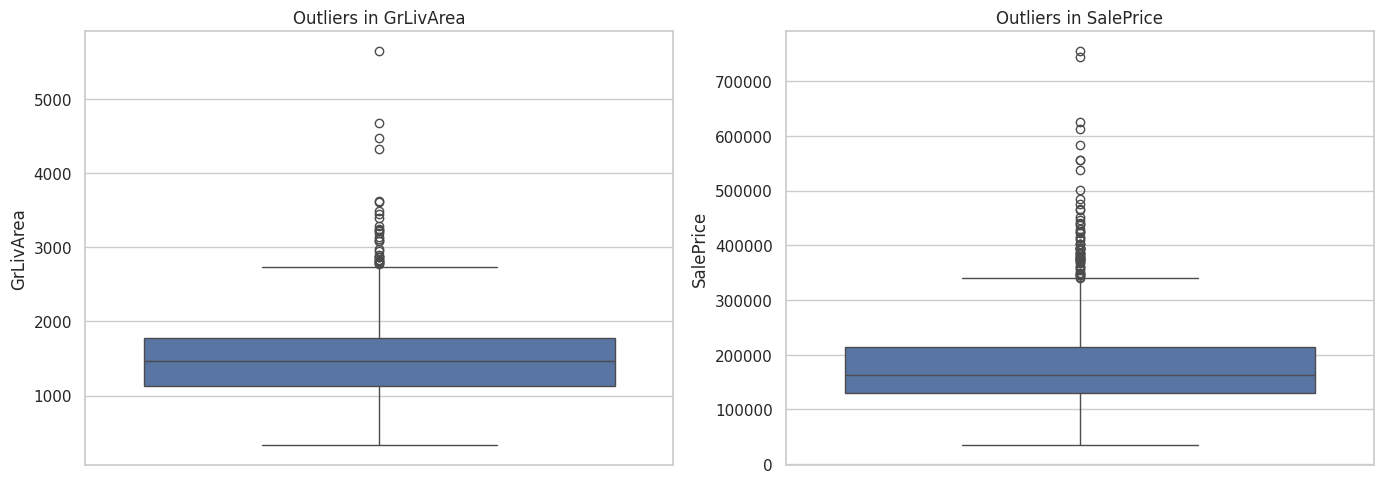

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=df['GrLivArea'], ax=axes[0])
axes[0].set_title('Outliers in GrLivArea')

sns.boxplot(y=df['SalePrice'], ax=axes[1])
axes[1].set_title('Outliers in SalePrice')

plt.tight_layout()
plt.show()

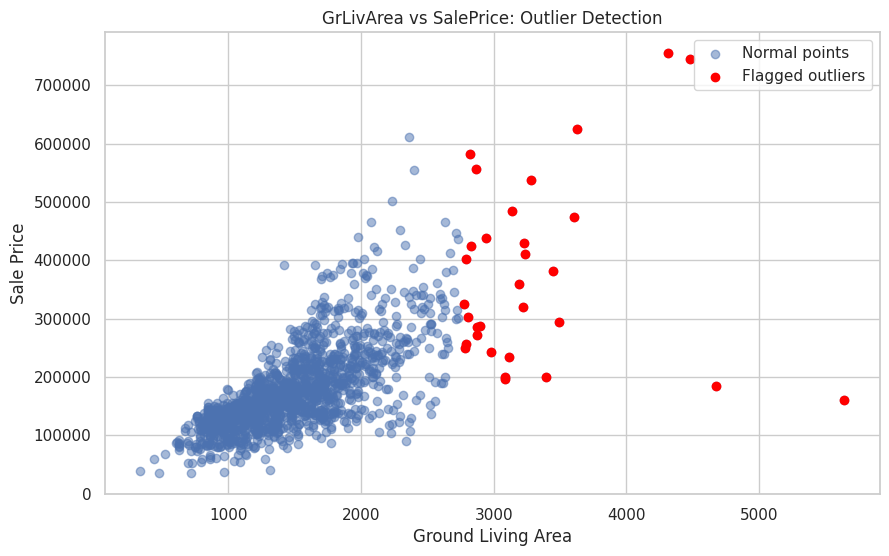

In [41]:
iqr_indices = iqr_outliers(df['GrLivArea'])
zscore_indices = zscore_outliers(df['GrLivArea'])

flagged_indices = set(iqr_indices) | set(zscore_indices)

plt.figure(figsize=(10, 6))
plt.scatter(df['GrLivArea'], df['SalePrice'], alpha=0.5, label='Normal points')
plt.scatter(
    df.loc[list(flagged_indices), 'GrLivArea'],
    df.loc[list(flagged_indices), 'SalePrice'],
    color='red',
    label='Flagged outliers'
)

plt.title('GrLivArea vs SalePrice: Outlier Detection')
plt.xlabel('Ground Living Area')
plt.ylabel('Sale Price')
plt.legend()
plt.show()

In [42]:
dup_count = df.duplicated().sum()

print("Number of duplicate rows:", dup_count)

if dup_count > 0:
    df = df.drop_duplicates()
    print("Shape after removing duplicates:", df.shape)

Number of duplicate rows: 0


In [43]:
for col in categorical_cols:
    print("\nColumn:", col)
    print(df[col].dropna().unique())


Column: MSZoning
['RL' 'RM' 'C (all)' 'FV' 'RH']

Column: Street
['Pave' 'Grvl']

Column: Alley
['Grvl' 'Pave']

Column: LotShape
['Reg' 'IR1' 'IR2' 'IR3']

Column: LandContour
['Lvl' 'Bnk' 'Low' 'HLS']

Column: Utilities
['AllPub' 'NoSeWa']

Column: LotConfig
['Inside' 'FR2' 'Corner' 'CulDSac' 'FR3']

Column: LandSlope
['Gtl' 'Mod' 'Sev']

Column: Neighborhood
['CollgCr' 'Veenker' 'Crawfor' 'NoRidge' 'Mitchel' 'Somerst' 'NWAmes'
 'OldTown' 'BrkSide' 'Sawyer' 'NridgHt' 'NAmes' 'SawyerW' 'IDOTRR'
 'MeadowV' 'Edwards' 'Timber' 'Gilbert' 'StoneBr' 'ClearCr' 'NPkVill'
 'Blmngtn' 'BrDale' 'SWISU' 'Blueste']

Column: Condition1
['Norm' 'Feedr' 'PosN' 'Artery' 'RRAe' 'RRNn' 'RRAn' 'PosA' 'RRNe']

Column: Condition2
['Norm' 'Artery' 'RRNn' 'Feedr' 'PosN' 'PosA' 'RRAn' 'RRAe']

Column: BldgType
['1Fam' '2fmCon' 'Duplex' 'TwnhsE' 'Twnhs']

Column: HouseStyle
['2Story' '1Story' '1.5Fin' '1.5Unf' 'SFoyer' 'SLvl' '2.5Unf' '2.5Fin']

Column: RoofStyle
['Gable' 'Hip' 'Gambrel' 'Mansard' 'Flat' 'Shed

In [44]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("Columns with missing values:")
print(missing)
print("\nTotal missing values:", df.isnull().sum().sum())

Columns with missing values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

Total missing values: 7829


In [45]:
absent_columns = [
    'PoolQC',
    'Alley',
    'Fence',
    'FireplaceQu',
    'GarageType'
]

for col in absent_columns:
    df[col] = df[col].fillna('None')

print(df[absent_columns].isnull().sum())

PoolQC         0
Alley          0
Fence          0
FireplaceQu    0
GarageType     0
dtype: int64


In [46]:
df['LotFrontage'] = df['LotFrontage'].fillna(
    df.groupby('Neighborhood')['LotFrontage'].transform('median')
)

df['LotFrontage'] = df['LotFrontage'].fillna(df['LotFrontage'].median())

df['MasVnrArea'] = df['MasVnrArea'].fillna(df['MasVnrArea'].median())

print(df[['LotFrontage', 'MasVnrArea']].isnull().sum())

LotFrontage    0
MasVnrArea     0
dtype: int64


In [47]:
print("YearBuilt greater than YrSold:")
print(df[df['YearBuilt'] > df['YrSold']][['YearBuilt', 'YrSold']])

area_columns = ['LotArea', 'GrLivArea', 'TotalBsmtSF', 'GarageArea']

for col in area_columns:
    print(col, "negative values:", (df[col] < 0).sum())

YearBuilt greater than YrSold:
Empty DataFrame
Columns: [YearBuilt, YrSold]
Index: []
LotArea negative values: 0
GrLivArea negative values: 0
TotalBsmtSF negative values: 0
GarageArea negative values: 0


In [48]:
remaining_missing = df.isnull().sum()
remaining_missing = remaining_missing[remaining_missing > 0].sort_values(ascending=False)

print(remaining_missing)
print("Total remaining missing values:", df.isnull().sum().sum())

MiscFeature     1406
MasVnrType       872
GarageYrBlt       81
GarageFinish      81
GarageCond        81
GarageQual        81
BsmtExposure      38
BsmtFinType2      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
Electrical         1
dtype: int64
Total remaining missing values: 2790


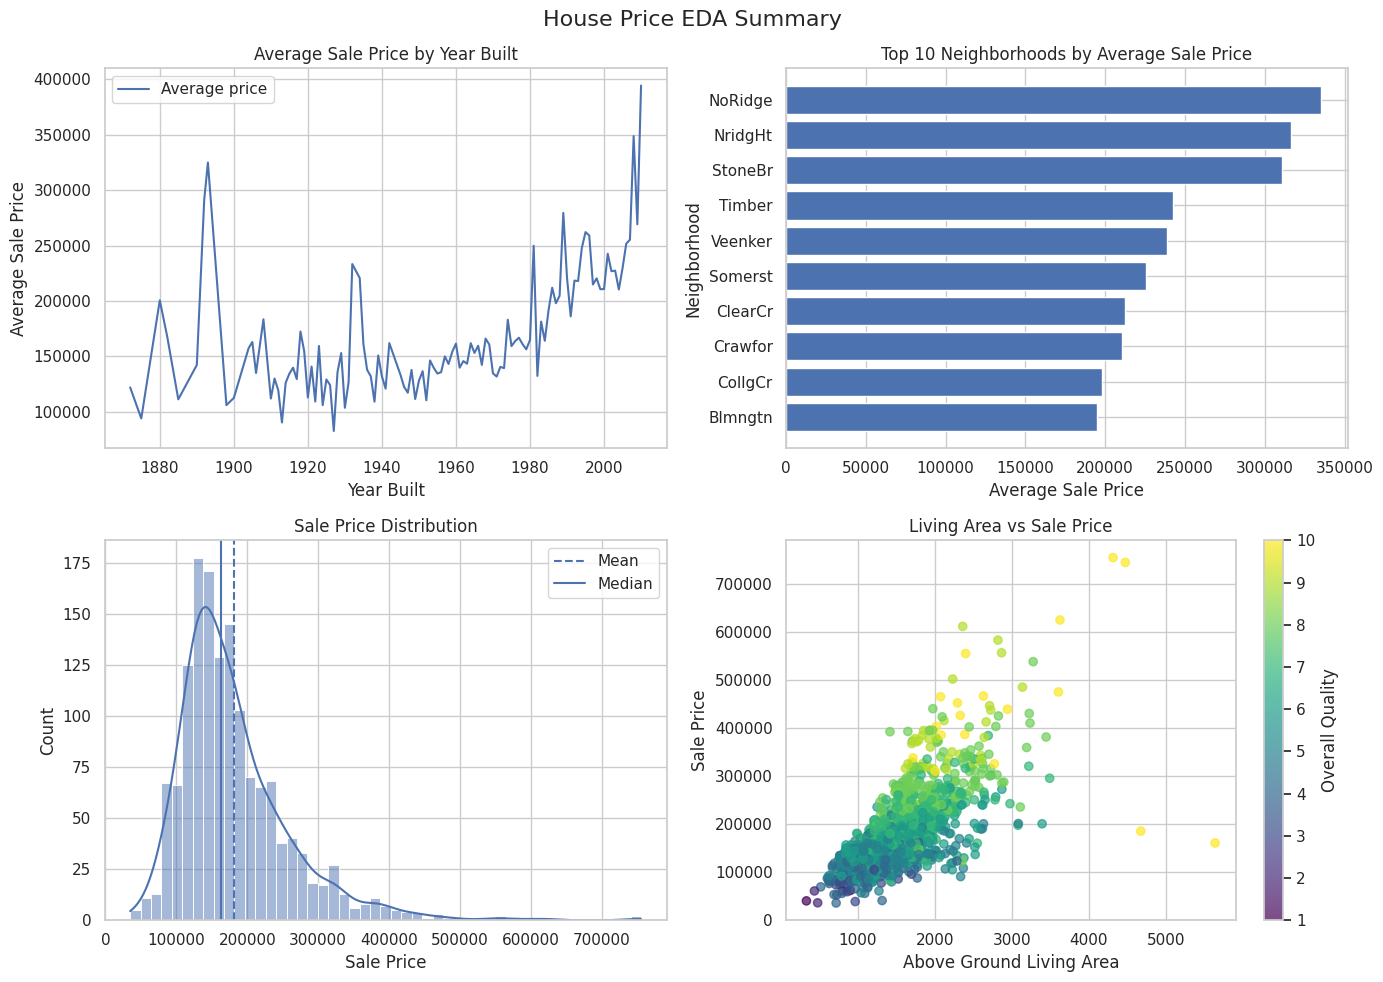

In [49]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

yearly_prices = df.groupby('YearBuilt')['SalePrice'].mean()

axes[0, 0].plot(yearly_prices.index, yearly_prices.values, label='Average price')
axes[0, 0].set_title('Average Sale Price by Year Built')
axes[0, 0].set_xlabel('Year Built')
axes[0, 0].set_ylabel('Average Sale Price')
axes[0, 0].legend()

neighborhood_prices = df.groupby('Neighborhood')['SalePrice'].mean().sort_values(ascending=False).head(10)

axes[0, 1].barh(neighborhood_prices.index, neighborhood_prices.values)
axes[0, 1].set_title('Top 10 Neighborhoods by Average Sale Price')
axes[0, 1].set_xlabel('Average Sale Price')
axes[0, 1].set_ylabel('Neighborhood')
axes[0, 1].invert_yaxis()

sns.histplot(df['SalePrice'], kde=True, ax=axes[1, 0])
axes[1, 0].axvline(df['SalePrice'].mean(), linestyle='--', label='Mean')
axes[1, 0].axvline(df['SalePrice'].median(), linestyle='-', label='Median')
axes[1, 0].set_title('Sale Price Distribution')
axes[1, 0].set_xlabel('Sale Price')
axes[1, 0].legend()

scatter = axes[1, 1].scatter(
    df['GrLivArea'],
    df['SalePrice'],
    c=df['OverallQual'],
    cmap='viridis',
    alpha=0.7
)
axes[1, 1].set_title('Living Area vs Sale Price')
axes[1, 1].set_xlabel('Above Ground Living Area')
axes[1, 1].set_ylabel('Sale Price')
fig.colorbar(scatter, ax=axes[1, 1], label='Overall Quality')

fig.suptitle('House Price EDA Summary', fontsize=16)
plt.tight_layout()
plt.savefig('eda_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()

In [50]:
print("DATASET SUMMARY")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nSALE PRICE ANALYSIS")
print("Mean:", df['SalePrice'].mean())
print("Median:", df['SalePrice'].median())
print("Skewness:", df['SalePrice'].skew())

print("\nTOP 5 FEATURES CORRELATED WITH SALE PRICE")
print(top_corr.head(5))

print("\nTOP 5 NEIGHBORHOODS BY AVERAGE SALE PRICE")
print(df.groupby('Neighborhood')['SalePrice'].mean().sort_values(ascending=False).head(5))

print("\nOUTLIER COUNTS")
for col in ['GrLivArea', 'SalePrice']:
    print(col)
    print("IQR:", len(iqr_outliers(df[col])))
    print("Z-score:", len(zscore_outliers(df[col])))

print("\nDATA QUALITY")
print("Duplicate rows:", df.duplicated().sum())
print("Remaining missing values:", df.isnull().sum().sum())

DATASET SUMMARY
Rows: 1460
Columns: 82

SALE PRICE ANALYSIS
Mean: 180921.19589041095
Median: 163000.0
Skewness: 1.8828757597682129

TOP 5 FEATURES CORRELATED WITH SALE PRICE
LogSalePrice    0.948374
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
Name: SalePrice, dtype: float64

TOP 5 NEIGHBORHOODS BY AVERAGE SALE PRICE
Neighborhood
NoRidge    335295.317073
NridgHt    316270.623377
StoneBr    310499.000000
Timber     242247.447368
Veenker    238772.727273
Name: SalePrice, dtype: float64

OUTLIER COUNTS
GrLivArea
IQR: 31
Z-score: 16
SalePrice
IQR: 61
Z-score: 22

DATA QUALITY
Duplicate rows: 0
Remaining missing values: 2790


# Conclusion

This project performed Exploratory Data Analysis (EDA) on the Ames Housing Dataset using Python.

The dataset initially contained 1,460 rows and 81 columns.

The analysis included:
- Classification of numerical, categorical, and ordinal variables.
- Descriptive statistical analysis.
- Histograms, KDE plots, and boxplots.
- Correlation and covariance analysis.
- Scatter plots and pair plots.
- Correlation heatmap.
- Outlier detection using IQR and Z-score methods.
- Data quality checks and missing-value handling.
- A final dashboard summarizing important findings.

## Key Findings

1. The distribution of SalePrice was examined to understand its shape and skewness.
2. The strongest features associated with SalePrice were identified using correlation analysis.
3. Differences in house prices across neighborhoods were examined.
4. Outliers were detected using IQR and Z-score methods.
5. Missing values and data quality issues were investigated.
6. A dashboard was created to summarize the major relationships in the dataset.

## Final Conclusion

Exploratory Data Analysis helped us understand the patterns, relationships, distributions, and quality issues in the Ames Housing Dataset. The project demonstrated how statistical methods and visualizations can help identify factors associated with house prices without using machine learning.